# ПРЕДОБРАБОТКА ДАННЫХ

## ВИЗУАЛИЗИРУЕМ ДАННЫЕ, НАЙДЕМ ОСНОВНЫЕ СТАТИСТИКИ

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from pathlib import Path




In [3]:

ratings_csv = Path("~/Workspace/ML_Project/data/row/ml-latest-small/ratings.csv")
movies_csv = Path("~/Workspace/ML_Project/data/row/ml-latest-small/movies.csv")
tags_csv = Path("~/Workspace/ML_Project/data/row/ml-latest-small/tags.csv")
links_csv = Path("~/Workspace/ML_Project/data/row/ml-latest-small/links.csv")

ratings = pd.read_csv(ratings_csv)
movies = pd.read_csv(movies_csv)
tags = pd.read_csv(tags_csv)
links = pd.read_csv(links_csv)

print(ratings.head(3), "\n")
print(tags.head(10), "\n")
print(links.head(3), "\n")
print(movies.head(3), "\n")


   userId  movieId  rating  timestamp
0       1        1     4.0  964982703
1       1        3     4.0  964981247
2       1        6     4.0  964982224 

   userId  movieId                tag   timestamp
0       2    60756              funny  1445714994
1       2    60756    Highly quotable  1445714996
2       2    60756       will ferrell  1445714992
3       2    89774       Boxing story  1445715207
4       2    89774                MMA  1445715200
5       2    89774          Tom Hardy  1445715205
6       2   106782              drugs  1445715054
7       2   106782  Leonardo DiCaprio  1445715051
8       2   106782    Martin Scorsese  1445715056
9       7    48516       way too long  1169687325 

   movieId  imdbId   tmdbId
0        1  114709    862.0
1        2  113497   8844.0
2        3  113228  15602.0 

   movieId                    title  \
0        1         Toy Story (1995)   
1        2           Jumanji (1995)   
2        3  Grumpier Old Men (1995)   

                       

In [4]:
rating_mean = ratings["rating"].mean()
rating_median = ratings["rating"].median()
rating_std = ratings["rating"].std()
rating_mode = ratings["rating"].mode().iloc[0]

rating_cv = rating_std / rating_mean * 100

quantile1 = ratings["rating"].quantile(0.25)
quantile3 = ratings["rating"].quantile(0.75)

iqr = quantile3 - quantile1
print(f"Статистики для колонки ratings: \n")
print(f"Средняя оценка: {rating_mean:.2f}")
print(f"Медианная оценка: {rating_median:.2f}")
print(f"Мода оценки: {rating_mode:.2f}")
print(f"25-й перцентиль (Q1): {quantile1:.2f}")
print(f"75-й перцентиль (Q3): {quantile3:.2f}")
print(f"Межквартильный размах (IQR): {iqr:.2f}")
print(f"Стандартное отклонение: {rating_std:.2f}")
print(f"Коэффициент вариации: {rating_cv:.2f}%")

Статистики для колонки ratings: 

Средняя оценка: 3.50
Медианная оценка: 3.50
Мода оценки: 4.00
25-й перцентиль (Q1): 3.00
75-й перцентиль (Q3): 4.00
Межквартильный размах (IQR): 1.00
Стандартное отклонение: 1.04
Коэффициент вариации: 29.77%


### Гистограмма

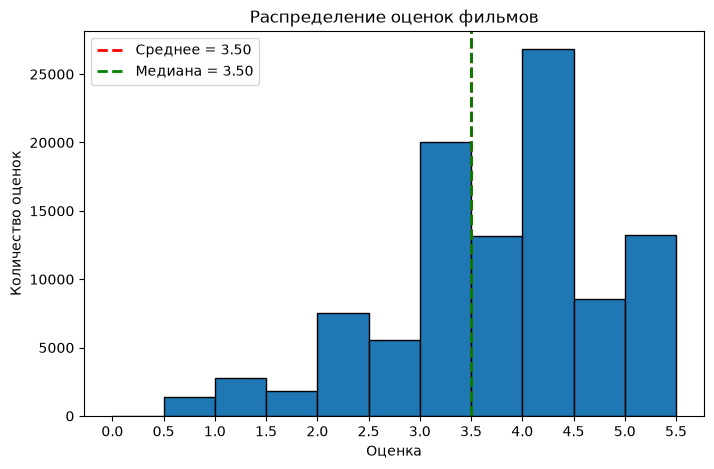

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(
    ratings["rating"],
    bins=[0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5],
    edgecolor="black"
)

plt.axvline(
    rating_mean,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Среднее = {rating_mean:.2f}"
)

plt.axvline(
    rating_median,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Медиана = {rating_median:.2f}"
)


plt.title("Распределение оценок фильмов")
plt.xlabel("Оценка")
plt.ylabel("Количество оценок")
plt.xticks(
    [0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5]
)
plt.legend()

plt.show()

### График box-and-whiskers

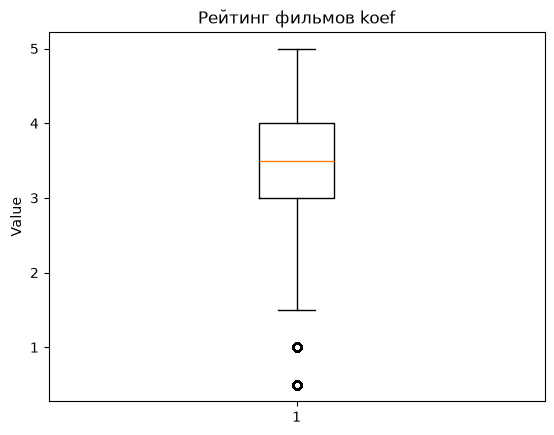

In [6]:
plt.boxplot(ratings["rating"])
plt.ylabel("Value")
plt.title("Рейтинг фильмов koef")
plt.show()

### Оценки 1, 0.5 нельзя считать выбросами, поэтому коэф примем равным 3

In [7]:
print(ratings[(ratings["rating"] > quantile3 + 1.5*iqr) | (ratings["rating"] < quantile1 - 1.5*iqr)])


        userId  movieId  rating   timestamp
205          1     3176     1.0   964983504
261          3       31     0.5  1306463578
262          3      527     0.5  1306464275
263          3      647     0.5  1306463619
264          3      688     0.5  1306464228
...        ...      ...     ...         ...
100374     610    68319     1.0  1493845505
100415     610    72424     0.5  1493849030
100426     610    74075     1.0  1493848880
100734     610   120635     1.0  1493850489
100797     610   145951     0.5  1493849019

[4181 rows x 4 columns]


In [8]:
print(ratings[(ratings["rating"] > quantile3 + 3*iqr) | (ratings["rating"] < quantile1 - 3*iqr)])

Empty DataFrame
Columns: [userId, movieId, rating, timestamp]
Index: []


In [9]:
merge_movies = ratings.merge(
    movies,
    on="movieId"
)
unique_genres = (
    merge_movies['genres']
    .dropna()
    .str.split('|')
    .explode()
    .unique()
)

print(sorted(unique_genres))
print(f"Фильмы без жанра: \n")
print(movies[movies['genres'] == '(no genres listed)'])
print(movies[movies['genres'] == '(no genres listed)'].count())


['(no genres listed)', 'Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']
Фильмы без жанра: 

      movieId                                              title  \
8517   114335                                  La cravate (1957)   
8684   122888                                     Ben-hur (2016)   
8687   122896  Pirates of the Caribbean: Dead Men Tell No Tal...   
8782   129250                                  Superfast! (2015)   
8836   132084                                Let It Be Me (1995)   
8902   134861               Trevor Noah: African American (2013)   
9033   141131                                   Guardians (2016)   
9053   141866                                  Green Room (2015)   
9070   142456                     The Brand New Testament (2015)   
9091   143410                                         Hyena Road   
913

In [10]:
movies['year'] = movies['title'].str.extract(r'\((\d{4})\)').astype('Int64')
print(f'\nПропуски, где название не подходит под шаблон: ')
print(movies['year'].isna().sum()) 
print(movies['title'][~movies['title'].str.contains(r'\((\d{4})\)')])



Пропуски, где название не подходит под шаблон: 
13
6059                                            Babylon 5
9031                                     Ready Player One
9091                                           Hyena Road
9138    The Adventures of Sherlock Holmes and Doctor W...
9179                                    Nocturnal Animals
9259                                             Paterson
9367                                            Moonlight
9448                                               The OA
9514                                               Cosmos
9515                              Maria Bamford: Old Baby
9518                    Death Note: Desu nôto (2006–2007)
9525                                    Generation Iron 2
9611                                         Black Mirror
Name: title, dtype: str


/tmp/ipykernel_65170/1615527934.py:4: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  print(movies['title'][~movies['title'].str.contains(r'\((\d{4})\)')])


In [11]:
years_fix = {
    'Babylon 5': 1993,
    'Ready Player One': 2018,
    'The Adventures of Sherlock Holmes and Doctor Watson': 1980,
    'Hyena Road': 2015,
    'Nocturnal Animals': 2016,
    'Paterson': 2016,
    'Moonlight': 2016,
    'The OA': 2016,
    'Cosmos': 2014,
    'Maria Bamford: Old Baby': 2017,
    'Death Note: Desu nôto (2006–2007)': 2006,
    'Generation Iron 2': 2017,
    'Black Mirror': 2013,
}

movies['year'] = movies['year'].fillna(movies['title'].map(years_fix)).astype('Int64')

print(movies['year'].isna().sum())

0



Средняя оценка по жанрам:
                 Genre  Average_Rating
0   (no genres listed)        3.489362
1               Action        3.447984
2            Adventure        3.508609
3            Animation        3.629937
4             Children        3.412956
5               Comedy        3.384721
6                Crime        3.658294
7          Documentary        3.797785
8                Drama        3.656184
9              Fantasy        3.491001
10           Film-Noir        3.920115
11              Horror        3.258195
12                IMAX        3.618335
13             Musical        3.563678
14             Mystery        3.632460
15             Romance        3.506511
16              Sci-Fi        3.455721
17            Thriller        3.493706
18                 War        3.808294
19             Western        3.583938


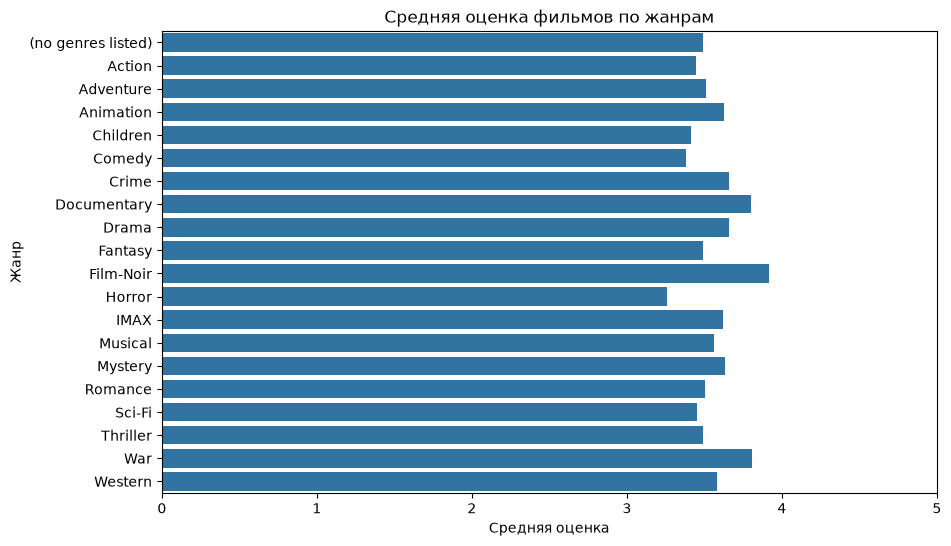

In [12]:
genre_ratings = []

for genre in sorted(unique_genres):
    ratings_by_genre = merge_movies[
        merge_movies['genres'].str.contains(
            genre,
            na=False,
            regex=False
        )
    ]

    genre_ratings.append({
        'Genre': genre,
        'Average_Rating': ratings_by_genre['rating'].mean()
    })

genre_ratings = pd.DataFrame(genre_ratings)

print("\nСредняя оценка по жанрам:")
print(genre_ratings)

# График
plt.figure(figsize=(10, 6))

sns.barplot(
    x='Average_Rating',
    y='Genre',
    data=genre_ratings
)

plt.title('Средняя оценка фильмов по жанрам')
plt.xlabel('Средняя оценка')
plt.ylabel('Жанр')
plt.xlim(0, 5)

plt.show()

### Распределение числа оценок 

In [13]:
movie_counts = ratings.groupby("movieId").size()
user_counts = ratings.groupby("userId").size()

print(movie_counts.describe())
print((movie_counts < 10).sum(), "фильмов с < 10 оценками")
print((user_counts < 5).sum(), "пользователей с < 5 оценками")

count    9724.000000
mean       10.369807
std        22.401005
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       329.000000
dtype: float64
7455 фильмов с < 10 оценками
0 пользователей с < 5 оценками


**77% фильмов** имеют < 10 оценок → любая модель, обученная на всём датасете, будет плохо работать на хвосте; 

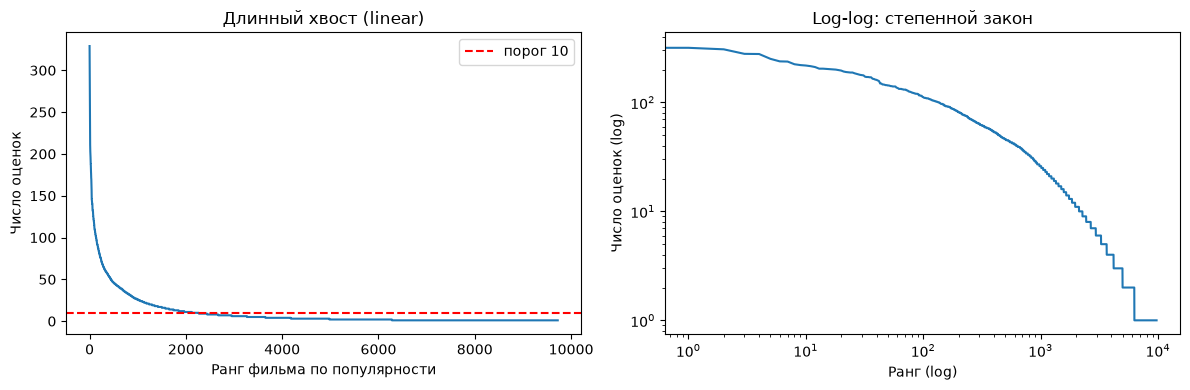

Топ-100 фильмов покрывают 16.1% всех оценок
Топ-500 фильмов покрывают 43.4% всех оценок
Топ-1000 фильмов покрывают 60.7% всех оценок
Топ-2000 фильмов покрывают 77.7% всех оценок


In [14]:
import matplotlib.pyplot as plt

movie_counts = ratings.groupby("movieId").size().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 1) Обычный (видно обрыв)
axes[0].plot(movie_counts.values)
axes[0].set_xlabel("Ранг фильма по популярности")
axes[0].set_ylabel("Число оценок")
axes[0].set_title("Длинный хвост (linear)")
axes[0].axhline(10, color="red", ls="--", label="порог 10")
axes[0].legend()

# 2) Log-log (видно степенной закон)
axes[1].loglog(movie_counts.values)
axes[1].set_xlabel("Ранг (log)")
axes[1].set_ylabel("Число оценок (log)")
axes[1].set_title("Log-log: степенной закон")

plt.tight_layout()
plt.show()

# Сколько оценок «покрывают» топ-N фильмов?
for n in [100, 500, 1000, 2000]:
    covered = movie_counts.head(n).sum() / movie_counts.sum()
    print(f"Топ-{n} фильмов покрывают {covered:.1%} всех оценок")

### Проверим пропуски и дубликаты

In [15]:
print("Ratings:")
print("NaN:")
print(ratings.isna().sum())
print("Duplicates:", ratings.duplicated().sum())

print("\nMovies:")
print("NaN:")
print(movies.isna().sum())
print("Duplicates:", movies.duplicated().sum())

print("\nTags:")
print("NaN:")
print(tags.isna().sum())
print("Duplicates:", tags.duplicated().sum())

print("\nLinks:")
print("NaN:")
print(links.isna().sum())
print("Duplicates:", links.duplicated().sum())



Ratings:
NaN:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64
Duplicates: 0

Movies:
NaN:
movieId    0
title      0
genres     0
year       0
dtype: int64
Duplicates: 0

Tags:
NaN:
userId       0
movieId      0
tag          0
timestamp    0
dtype: int64
Duplicates: 0

Links:
NaN:
movieId    0
imdbId     0
tmdbId     8
dtype: int64
Duplicates: 0


tmdbId пропуски удалять не будем, так как этот столбе не критичен для нашей работы 


### Дубликаты по паре (userId, movieId), целостность ключей и время

In [16]:
print("Дубликаты по (userId, movieId):", ratings.duplicated(subset=["userId", "movieId"]).sum())
ratings = (ratings.sort_values("timestamp")
                  .drop_duplicates(subset=["userId", "movieId"], keep="last")
                  .reset_index(drop=True))

print("movieId из ratings без записи в movies:", (~ratings["movieId"].isin(movies["movieId"])).sum())
print("movieId из tags без записи в movies:", (~tags["movieId"].isin(movies["movieId"])).sum())

ratings["datetime"] = pd.to_datetime(ratings["timestamp"], unit="s")
print("Период оценок:", ratings["datetime"].min(), "→", ratings["datetime"].max())

Дубликаты по (userId, movieId): 0
movieId из ratings без записи в movies: 0
movieId из tags без записи в movies: 0
Период оценок: 1996-03-29 18:36:55 → 2018-09-24 14:27:30


### Применим IsolationForest и LocalOutlierFactor для поиска аномалий

#### Прежде чем писать код, важно понять, кого именно вы ищете. В литературе по рекомендательным системам выделяют:

* Grey-sheep users — вкусы не совпадают ни с кем. Оценивают непопулярные фильмы, их вектор оценок слабо коррелирует с другими. Для CF они — шум: соседей нет, градиенты нестабильны.

* Power users / боты — аномально много оценок (сотни/тысячи), часто с низкой вариативностью (всё 5.0 или всё 1.0). Могут доминировать в лоссе.

* Спаммеры / тролли — ставят крайние оценки (1.0 или 5.0) почти всем фильмам, std ≈ 0, mean ≈ 1 или 5.

Не являются аномалией (важно!): пользователь, который поставил одну низкую оценку популярному фильму, или пользователь с малым числом оценок (он просто новый — это cold start, а не аномалия).

#### Признаки
mean_genre_deviation — среднее отклонение от жанрового среднего, ловит систематические нестандартные вкусы </br>
std_rating — разброс оценок пользователя, ловит спаммеров с низкой вариативностью</br>
mean_movie_popularity — средняя популярность оценённых фильмов, ловит grey sheep</br>
n_ratings</br>
mean_rating ловит тролли (всё 1.0) и всё-отличники (всё 5.0)	</br>
frac_extreme	доля крайних оценок (≤1.0 или ≥4.5)	</br>
genre_entropy	узкие vs хаотичные вкусы</br>

In [17]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

# ---------- 1. Агрегация до уровня пользователя ----------
df = ratings.merge(movies[["movieId", "genres"]], on="movieId")

# Средняя популярность фильмов (сколько оценок у фильма) — для grey-sheep
movie_counts = ratings.groupby("movieId").size().rename("movie_count")
df = df.merge(movie_counts, on="movieId", how="left")

# Среднее и std по жанру — для genre_deviation
genre_stats = df.groupby("genres")["rating"].agg(["mean", "std"]).rename(
    columns={"mean": "genre_mean", "std": "genre_std"}
)
df = df.merge(genre_stats, left_on="genres", right_index=True, how="left")
global_std = df["rating"].std()
df["genre_std"] = df["genre_std"].fillna(global_std).replace(0, global_std)
df["genre_deviation"] = (df["rating"] - df["genre_mean"]) / df["genre_std"]

# ---------- 2. Вектор признаков на пользователя ----------
def user_features(g):
    r = g["rating"]
    return pd.Series({
        "n_ratings":            len(r),
        "mean_rating":          r.mean(),
        "std_rating":           r.std(ddof=0),
        "frac_extreme":         ((r <= 1.0) | (r >= 4.5)).mean(),
        "mean_movie_popularity": g["movie_count"].mean(),
        "mean_genre_deviation": g["genre_deviation"].mean(),
    })

user_feats = df.groupby("userId").apply(user_features).reset_index()

# Энтропия жанров (разнообразие вкусов)
def genre_entropy(genres_series):
    counts = genres_series.str.split("|").explode().value_counts(normalize=True)
    return -(counts * np.log(counts + 1e-12)).sum()

entropy = df.groupby("userId")["genres"].apply(genre_entropy).rename("genre_entropy")
user_feats = user_feats.merge(entropy, on="userId")

print("Признаки пользователей:", user_feats.shape)
print(user_feats.describe().round(2))

# ---------- 3. Скейлинг + детекторы ----------
feature_cols = [
    "n_ratings", "mean_rating", "std_rating",
    "frac_extreme", "mean_movie_popularity",
    "mean_genre_deviation", "genre_entropy",
]
X = StandardScaler().fit_transform(user_feats[feature_cols])

iso = IsolationForest(contamination=0.02, random_state=42, n_jobs=-1)
iso_pred = iso.fit_predict(X)
user_feats["anomaly_iso"] = iso_pred

lof = LocalOutlierFactor(n_neighbors=20, contamination=0.02, n_jobs=-1)
lof_pred =lof.fit_predict(X)
user_feats["anomaly_lof"] = lof_pred

flags = user_feats.set_index("userId")[["anomaly_iso", "anomaly_lof"]]
df = df.join(flags, on="userId")
# ---------- 4. Диагностика ----------
n_iso = (user_feats["anomaly_iso"] == -1).sum()
n_lof = (user_feats["anomaly_lof"] == -1).sum()
n_both = ((user_feats["anomaly_iso"] == -1) & (user_feats["anomaly_lof"] == -1)).sum()
print(f"\nIF аномалий: {n_iso} из {len(user_feats)} ({n_iso/len(user_feats):.1%})")
print(f"LoF аномалий: {n_lof} из {len(user_feats)} ({n_lof/len(user_feats):.1%})")
print(f"Совпало (оба метода): {n_both}")

# Кто именно попал — посмотреть глазами
anom = user_feats[
    (user_feats["anomaly_iso"] == -1) | (user_feats["anomaly_lof"] == -1)
].sort_values("n_ratings", ascending=False)
print("\nТоп аномальных пользователей:")
print(anom.head(15).round(2).to_string(index=False))

Признаки пользователей: (610, 8)
       userId  n_ratings  mean_rating  std_rating  frac_extreme  \
count  610.00     610.00       610.00      610.00        610.00   
mean   305.50     165.30         3.66        0.92          0.32   
std    176.24     269.48         0.48        0.26          0.19   
min      1.00      20.00         1.27        0.00          0.00   
25%    153.25      35.00         3.36        0.73          0.18   
50%    305.50      70.50         3.69        0.89          0.30   
75%    457.75     168.00         4.00        1.07          0.43   
max    610.00    2698.00         5.00        2.06          1.00   

       mean_movie_popularity  mean_genre_deviation  genre_entropy  
count                 610.00                610.00         610.00  
mean                   79.85                  0.12           2.42  
std                    33.28                  0.45           0.14  
min                    10.00                 -2.20           1.68  
25%                    

### Признаки уровня оценки (для матрицы корреляций и PCA)

In [18]:


features = user_feats.drop(columns=['anomaly_iso', 'anomaly_lof', 'userId' ])
print(features.shape)
print(features.describe().round(2))

(610, 7)
       n_ratings  mean_rating  std_rating  frac_extreme  \
count     610.00       610.00      610.00        610.00   
mean      165.30         3.66        0.92          0.32   
std       269.48         0.48        0.26          0.19   
min        20.00         1.27        0.00          0.00   
25%        35.00         3.36        0.73          0.18   
50%        70.50         3.69        0.89          0.30   
75%       168.00         4.00        1.07          0.43   
max      2698.00         5.00        2.06          1.00   

       mean_movie_popularity  mean_genre_deviation  genre_entropy  
count                 610.00                610.00         610.00  
mean                   79.85                  0.12           2.42  
std                    33.28                  0.45           0.14  
min                    10.00                 -2.20           1.68  
25%                    55.76                 -0.15           2.35  
50%                    74.49                  0.15 

### Матрица корреляции 

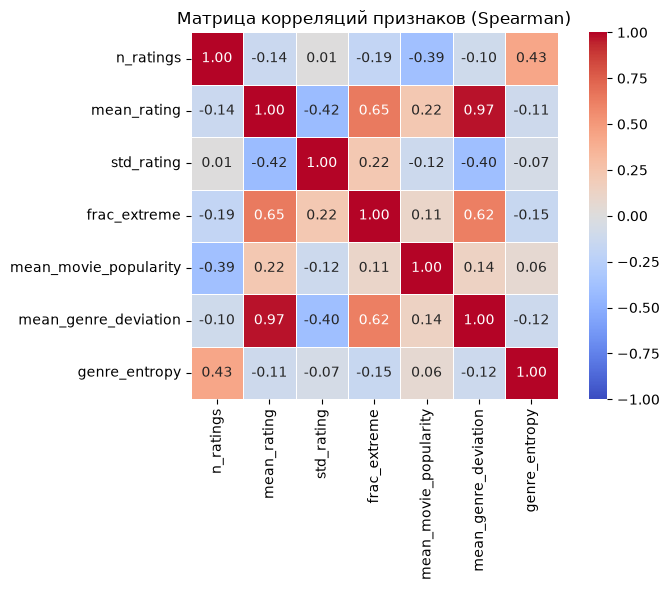

Пары с |corr| > 0.7:
mean_rating  mean_genre_deviation    0.972686
dtype: float64


In [19]:

num_cols = features.select_dtypes(include=[np.number]).columns
corr = features[num_cols].corr(method="spearman")  # Spearman устойчивее к выбросам

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="coolwarm",
    center=0, vmin=-1, vmax=1, square=True,
    linewidths=0.5,
)
plt.title("Матрица корреляций признаков (Spearman)")
plt.tight_layout()
plt.show()

# Диагностика: какие пары сильно коррелируют (мультиколлинеарность)
high_corr = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        .stack()
        .sort_values(ascending=False)
)
print("Пары с |corr| > 0.7:")
print(high_corr[high_corr.abs() > 0.7])

### Построим графики скоров для ISO и LOF и посмотрим какое количество аномалий в принципе присутствует в моей выборке<br>
LOF: <br>
-1.0	Норма<br>
-2.0    Аномалия<br>
-5.0	Сильная аномалия<br>
-0.5	Очень типичная точка<br>

ISO:<br>
-0.5    Аномалия<br>
0       Граница нормы<br>
0.5     Типичная точка<br>

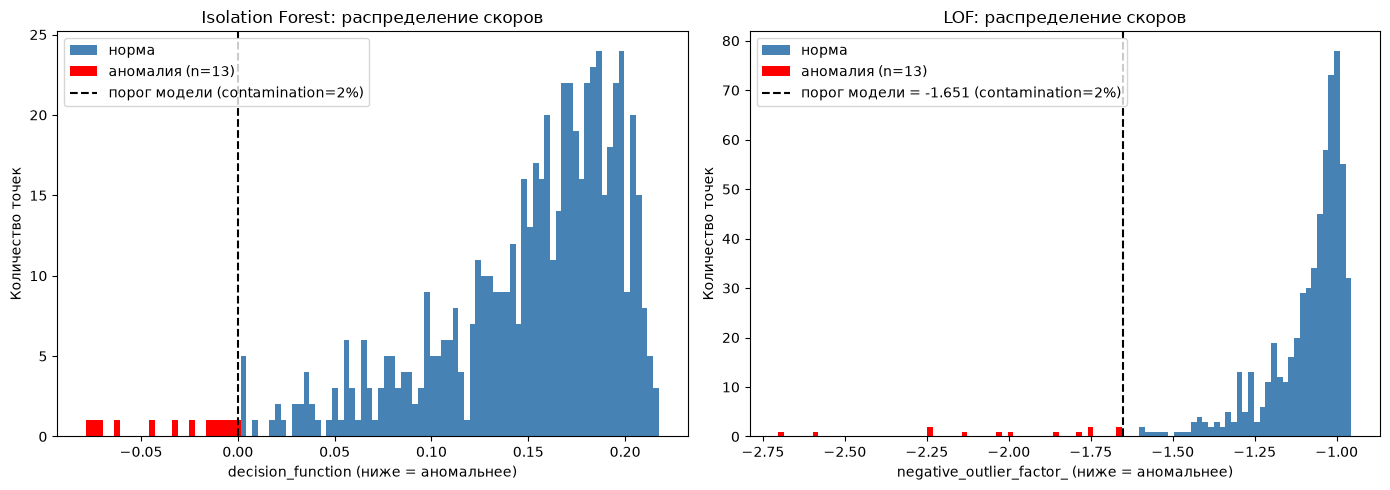

IF:  ниже порога 13 (2.13%) | predict == -1: 13
LoF: ниже порога 13 (2.13%) | predict == -1: 13
Совпало у обоих методов: 8


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cont = f"{iso.contamination:.0%}"

# ISO
scores_iso = iso.decision_function(X)  # чем ниже — тем аномальнее
thr_iso = 0.0                          # граница модели: decision_function < 0
flag_iso = scores_iso < thr_iso

bins = np.histogram_bin_edges(scores_iso, bins=100)
axes[0].hist([scores_iso[~flag_iso], scores_iso[flag_iso]], bins=bins, stacked=True,
             color=["steelblue", "red"], edgecolor="none",
             label=["норма", f"аномалия (n={flag_iso.sum()})"])
axes[0].axvline(thr_iso, color="black", linestyle="--",
                label=f"порог модели (contamination={cont})")
axes[0].set_title("Isolation Forest: распределение скоров")
axes[0].set_xlabel("decision_function (ниже = аномальнее)")
axes[0].set_ylabel("Количество точек")
axes[0].legend()

# LOF
scores_lof = lof.negative_outlier_factor_  # чем ниже — тем аномальнее
thr_lof = lof.offset_                      # граница модели
flag_lof = scores_lof < thr_lof

bins = np.histogram_bin_edges(scores_lof, bins=100)
axes[1].hist([scores_lof[~flag_lof], scores_lof[flag_lof]], bins=bins, stacked=True,
             color=["steelblue", "red"], edgecolor="none",
             label=["норма", f"аномалия (n={flag_lof.sum()})"])
axes[1].axvline(thr_lof, color="black", linestyle="--",
                label=f"порог модели = {thr_lof:.3f} (contamination={cont})")
axes[1].set_title("LOF: распределение скоров")
axes[1].set_xlabel("negative_outlier_factor_ (ниже = аномальнее)")
axes[1].set_ylabel("Количество точек")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"IF:  ниже порога {flag_iso.sum()} ({flag_iso.mean():.2%}) | predict == -1: {(iso.predict(X) == -1).sum()}")
print(f"LoF: ниже порога {flag_lof.sum()} ({flag_lof.mean():.2%}) | predict == -1: {(lof_pred == -1).sum()}")
print(f"Совпало у обоих методов: {(flag_iso & flag_lof).sum()}")

### Визуализируем уменьшив размерность методом главных компонент

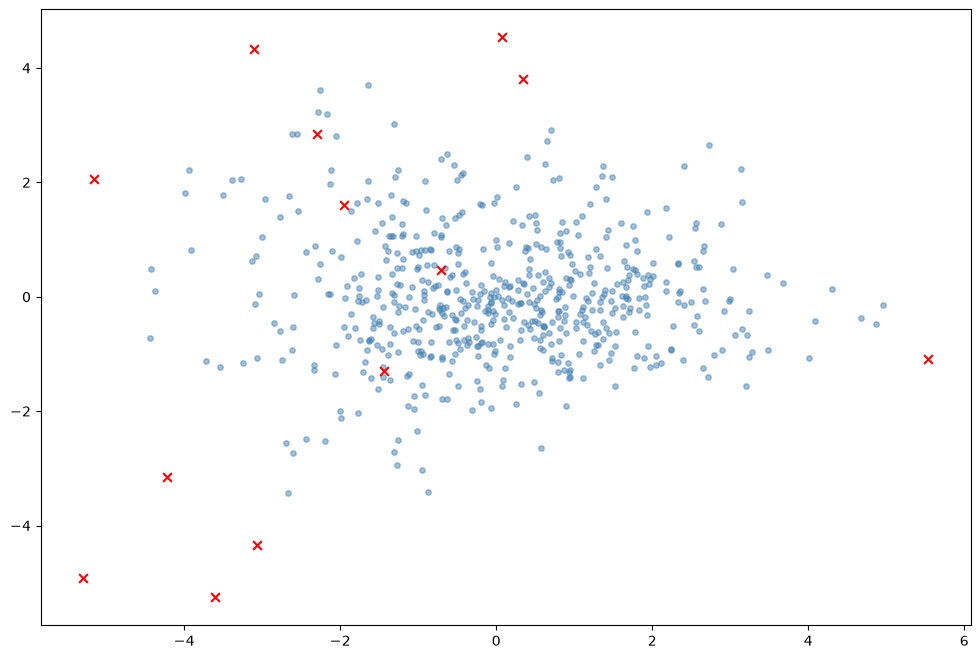

In [21]:
from sklearn.decomposition import PCA

pca_cols = list(features.columns)
X_pca_input = StandardScaler().fit_transform(features[pca_cols])

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_pca_input)

pca_df = pd.DataFrame(X_pca, columns=["pc1", "pc2"], index=user_feats.index)
pca_df["is_anomaly_lof"] = (user_feats["anomaly_lof"] == -1).values

normal = pca_df[~pca_df["is_anomaly_lof"]]
anomalies = pca_df[pca_df["is_anomaly_lof"]]

plt.figure(figsize=(12, 8))
plt.scatter(normal["pc1"], normal["pc2"], c="steelblue", s=15, alpha=0.5, label="Норма")
plt.scatter(anomalies["pc1"], anomalies["pc2"], c="red", s=40, marker="x",
            linewidths=1.5, label=f"Аномалия LoF (n={len(anomalies)})", zorder=3)
# дальше без изменений, в загрузках columns=pca_cols

## ФИНАЛЬНАЯ ПРЕДОБРАБОТКА ДЛЯ NCF И COLLABORATIVE FILTERING

Порядок: удаляем аномальных пользователей → k-core фильтр (холодный старт) → split по времени → индексы `uid`/`iid` по train → негативы для NCF-оценки → sparse-матрица для CF → проверки → сохранение.

Все параметры вынесены в первую ячейку раздела.

Что происходит по шагам и зачем

1. Удаление аномальных пользователей. Пользователи, которых отметили оба детектора (боты, люди, ставящие всем 5.0, и т. п.), задают модели странные закономерности. Берём пересечение двух методов, чтобы не выкинуть нормальных людей.

2. k-core фильтр. У фильма с двумя оценками нельзя выучить эмбеддинг или найти похожие фильмы, это шум. Поэтому отсекаем редкие фильмы и пользователей, повторяя шаги до стабильного состояния (после удаления фильмов у пользователей становится меньше оценок, и наоборот). Цена: каталог сильно сокращается.

3. Split по времени. Модель должна предсказывать будущее по прошлому. Случайный split даёт модели «подсмотреть» будущие оценки пользователя в обучении, и метрики получаются завышенными. Поэтому у каждого пользователя последние оценки идут в test, предыдущие в val, остальное в train. Фильмы, которых нет в train, из val/test убираем: эмбеддинга для них нет, оценить их нечем.

4. Индексы и like. Эмбеддинги и матрицы требуют номера подряд, 0..N-1, а настоящие userId и movieId идут с пропусками. Метка like (оценка не ниже 4.0) нужна, если вы захотите считать положительными только понравившиеся фильмы.

5. Негативы. Подробно ниже.

6. R_train и средние. Разреженная матрица пользователь × фильм нужна классическим методам (ALS, SVD, item-kNN). Средние помогают центрировать оценки и служат бейзлайном. Считаем всё только по train, чтобы в метрики не просочились val и test.

7. Проверки. Ловят ошибки в данных до обучения: пересечения train с val и test, ложные негативы, нарушение порядка по времени.

8. Сохранение. Фиксирует результат, чтобы обучающий код читал готовые файлы и все модели работали на одних и тех же данных.

Зачем нужны негативы

В датасете есть только факты взаимодействия: «пользователь оценил фильм». Записей вида «пользователь этот фильм не хочет» нет. Негативы нужны в двух местах, и они решают разные задачи.

Для обучения NCF. NCF учится отличать пары «пользователь, фильм», которые случились, от тех, что нет. Если показывать только положительные пары, проще всего выдавать «да» на любую, и модель ничему не научится. Поэтому к каждой положительной паре добавляют несколько случайных неоценённых фильмов с меткой 0 (обычно 4 на одну положительную). Это допущение: неоценённый фильм не обязательно не понравился, пользователь мог его просто не видеть. На практике такое допущение работает, потому что среди тысяч фильмов случайный чаще всего действительно неинтересен. Эти негативы не сохраняются в файл, а сэмплируются заново в каждую эпоху: свежие негативы дают лучше результат, чем один раз зафиксированные.

In [22]:
import json
from scipy.sparse import csr_matrix, save_npz

SEED = 42
OUT_DIR = Path("~/Workspace/ML_Project/data/processed").expanduser()
OUT_DIR.mkdir(parents=True, exist_ok=True)

ANOMALY_RULE = "both"      # "both" | "lof" | "iso" | "any" | "none"
MIN_USER_RATINGS = 5
MIN_ITEM_RATINGS = 10
VAL_FRAC = 0.1
TEST_FRAC = 0.1
N_NEG_EVAL = 99
LIKE_THRESHOLD = 4.0

### Удаляем аномальных пользователей

In [23]:
iso_flag = user_feats["anomaly_iso"] == -1
lof_flag = user_feats["anomaly_lof"] == -1
rules = {
    "both": iso_flag & lof_flag,
    "lof": lof_flag,
    "iso": iso_flag,
    "any": iso_flag | lof_flag,
    "none": pd.Series(False, index=user_feats.index),
}
bad_users = user_feats.loc[rules[ANOMALY_RULE], "userId"].tolist()

clean = ratings[~ratings["userId"].isin(bad_users)].copy()
print(f"Правило: {ANOMALY_RULE} | удалено пользователей: {len(bad_users)} | оценок: {len(ratings)} → {len(clean)}")
print(user_feats.loc[user_feats["userId"].isin(bad_users),
                     ["userId", "n_ratings", "mean_rating", "std_rating", "frac_extreme"]]
      .round(2).to_string(index=False))

Правило: both | удалено пользователей: 8 | оценок: 100836 → 93659
 userId  n_ratings  mean_rating  std_rating  frac_extreme
      3       39.0         2.44        2.06          0.90
     53       20.0         5.00        0.00          1.00
     85       34.0         3.71        1.34          0.47
    175       24.0         3.54        1.66          0.62
    414     2698.0         3.39        0.93          0.14
    442       20.0         1.27        0.68          0.55
    448     1864.0         2.85        1.03          0.12
    599     2478.0         2.64        0.82          0.07


### Холодный старт: итеративный k-core фильтр

In [24]:
def k_core(d, min_u, min_i):
    while True:
        n0 = len(d)
        d = d[d.groupby("movieId")["rating"].transform("size") >= min_i]
        d = d[d.groupby("userId")["rating"].transform("size") >= min_u]
        if len(d) == n0:
            return d

def describe(d, name):
    nu, ni = d["userId"].nunique(), d["movieId"].nunique()
    print(f"{name}: users={nu}, items={ni}, ratings={len(d)}, sparsity={1 - len(d) / (nu * ni):.2%}")

describe(clean, "до фильтра   ")
clean = k_core(clean, MIN_USER_RATINGS, MIN_ITEM_RATINGS)
describe(clean, "после фильтра")

до фильтра   : users=602, items=8967, ratings=93659, sparsity=98.26%
после фильтра: users=602, items=2097, ratings=75509, sparsity=94.02%


### Split по времени: у каждого пользователя последние оценки → test, перед ними → val, остальное → train

In [25]:
clean = clean.sort_values(["userId", "timestamp", "movieId"]).reset_index(drop=True)
pos = clean.groupby("userId").cumcount()
n_u = clean.groupby("userId")["rating"].transform("size")
n_test = np.maximum(1, (n_u * TEST_FRAC).round()).astype(int)
n_val = np.maximum(1, (n_u * VAL_FRAC).round()).astype(int)

clean["split"] = np.select(
    [pos >= n_u - n_test, pos >= n_u - n_test - n_val], ["test", "val"], default="train"
)

# фильмы, которых нет в train, выбрасываем из val/test (их эмбеддинг не обучить)
known_items = set(clean.loc[clean["split"] == "train", "movieId"])
mask = (clean["split"] == "train") | clean["movieId"].isin(known_items)
print("Удалено из val/test из-за фильмов вне train:", (~mask).sum())
clean = clean[mask].reset_index(drop=True)
print(clean["split"].value_counts())

Удалено из val/test из-за фильмов вне train: 0
split
train    60419
val       7545
test      7545
Name: count, dtype: int64


### Индексы uid / iid (по train) и бинарная метка like

 Индексы uid (userId new) iid (movieId new) нужны чтобы переобозначить последовательность после очистки

In [26]:
train_ids = clean[clean["split"] == "train"]
uid_map = {u: i for i, u in enumerate(sorted(train_ids["userId"].unique()))}
iid_map = {m: i for i, m in enumerate(sorted(train_ids["movieId"].unique()))}
n_users, n_items = len(uid_map), len(iid_map)

clean["uid"] = clean["userId"].map(uid_map)
clean["iid"] = clean["movieId"].map(iid_map)
clean["like"] = (clean["rating"] >= LIKE_THRESHOLD).astype(int)

train, val, test = (clean[clean["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"])
print(f"users={n_users}, items={n_items} | train={len(train)}, val={len(val)}, test={len(test)}")

users=602, items=2097 | train=60419, val=7545, test=7545


### Негативы для оценки NCF: для каждой строки val/test — 99 фильмов, которые пользователь не оценивал

In [27]:
rng = np.random.default_rng(SEED)
all_items = np.arange(n_items)
seen = {u: g.to_numpy() for u, g in clean.groupby("uid")["iid"]}
pool = {u: np.setdiff1d(all_items, s, assume_unique=True) for u, s in seen.items()}
assert min(len(p) for p in pool.values()) >= N_NEG_EVAL, "у пользователя слишком мало неоценённых фильмов"

def sample_negatives(d):
    return np.stack([rng.choice(pool[u], N_NEG_EVAL, replace=False) for u in d["uid"]]).astype(np.int32)

val_neg, test_neg = sample_negatives(val), sample_negatives(test)
print(val_neg.shape, test_neg.shape)

(7545, 99) (7545, 99)


### Sparse-матрица и базовые статистики для CF (только train)

In [28]:
R_train = csr_matrix(
    (train["rating"].to_numpy(dtype=np.float32), (train["uid"].to_numpy(), train["iid"].to_numpy())),
    shape=(n_users, n_items),
)
global_mean = float(train["rating"].mean())
user_mean = train.groupby("uid")["rating"].mean().reindex(range(n_users)).to_numpy()
item_mean = train.groupby("iid")["rating"].mean().reindex(range(n_items)).to_numpy()

print(f"R_train: {R_train.shape}, nnz={R_train.nnz}, density={R_train.nnz / (n_users * n_items):.2%}")
print(f"global_mean={global_mean:.3f}, NaN в user_mean/item_mean: {np.isnan(user_mean).sum()}/{np.isnan(item_mean).sum()}")

R_train: (602, 2097), nnz=60419, density=4.79%
global_mean=3.608, NaN в user_mean/item_mean: 0/0


### Проверки

In [29]:
assert clean[["uid", "iid"]].notna().all().all()
assert not clean.duplicated(["uid", "iid"]).any()

assert R_train[val["uid"].to_numpy(), val["iid"].to_numpy()].sum() == 0
assert R_train[test["uid"].to_numpy(), test["iid"].to_numpy()].sum() == 0

full = csr_matrix((np.ones(len(clean)), (clean["uid"].to_numpy(), clean["iid"].to_numpy())),
                  shape=(n_users, n_items))
for d, neg in [(val, val_neg), (test, test_neg)]:
    rows = np.repeat(d["uid"].to_numpy(), N_NEG_EVAL)
    assert full[rows, neg.ravel()].sum() == 0

t_train = train.groupby("uid")["timestamp"].max()
assert (val["timestamp"].to_numpy() >= t_train.loc[val["uid"]].to_numpy()).all()
t_tv = pd.concat([train, val]).groupby("uid")["timestamp"].max()
assert (test["timestamp"].to_numpy() >= t_tv.loc[test["uid"]].to_numpy()).all()

print("Все проверки пройдены")
print(f"Доля like в train: {train['like'].mean():.1%}")

Все проверки пройдены
Доля like в train: 52.6%


### Сохранение

In [30]:
cols = ["uid", "iid", "userId", "movieId", "rating", "like", "timestamp"]
for name, d in [("train", train), ("val", val), ("test", test)]:
    d[cols].to_csv(OUT_DIR / f"{name}.csv", index=False)

np.save(OUT_DIR / "val_neg.npy", val_neg)
np.save(OUT_DIR / "test_neg.npy", test_neg)
save_npz(OUT_DIR / "R_train.npz", R_train)
np.savez(OUT_DIR / "train_stats.npz", global_mean=global_mean, user_mean=user_mean, item_mean=item_mean)

pd.DataFrame({"userId": list(uid_map), "uid": list(uid_map.values())}).to_csv(OUT_DIR / "users.csv", index=False)

genre_dummies = movies["genres"].str.get_dummies("|")
items_out = (movies[["movieId", "title", "year", "genres"]]
             .join(genre_dummies)
             .assign(iid=movies["movieId"].map(iid_map))
             .dropna(subset=["iid"])
             .astype({"iid": int})
             .sort_values("iid"))
items_out.to_csv(OUT_DIR / "items.csv", index=False)

meta = {
    "n_users": n_users, "n_items": n_items,
    "n_train": len(train), "n_val": len(val), "n_test": len(test),
    "n_neg_eval": N_NEG_EVAL, "like_threshold": LIKE_THRESHOLD,
    "anomaly_rule": ANOMALY_RULE, "removed_users": len(bad_users),
    "min_user_ratings": MIN_USER_RATINGS, "min_item_ratings": MIN_ITEM_RATINGS,
    "global_mean": global_mean, "seed": SEED,
}
json.dump(meta, open(OUT_DIR / "meta.json", "w"), indent=2)

print(sorted(p.name for p in OUT_DIR.iterdir()))

['R_train.npz', 'items.csv', 'meta.json', 'test.csv', 'test_neg.npy', 'train.csv', 'train_stats.npz', 'users.csv', 'val.csv', 'val_neg.npy']


### Что получилось на выходе
- `train.csv`, `val.csv`, `test.csv` — колонки `uid, iid, userId, movieId, rating, like, timestamp`
- `val_neg.npy`, `test_neg.npy` — для каждой строки val/test 99 негативных `iid` (оценка NCF: HR@K / NDCG@K на 100 кандидатах)
- `R_train.npz` — scipy CSR (users × items) с оценками из train, для ALS / SVD / item-kNN
- `train_stats.npz` — глобальное среднее и средние по пользователям и фильмам (только train)
- `items.csv` — `iid`, название, год, жанры (multi-hot) для гибридных моделей
- `users.csv` (маппинг `userId → uid`), `meta.json` (размеры и параметры)

Негативы для обучения NCF сэмплируются на лету: любые пары (uid, iid), которых нет в `R_train`.